<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/06-sobreajuste/solucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Solución 1.6 · Cuando el modelo se aprende las respuestas

**Serie:** Del Excel al Machine Learning · **Temporada 1** · 🎬 Video próximamente

Estas son las respuestas del ejercicio. Si la tuya es distinta pero da el mismo resultado, ¡también está bien! En programación suele haber más de una forma de llegar a la respuesta.

### Prepara los datos

Ejecuta estas cinco celdas. Dejan listas `entreno`, `prueba` y la función `evaluar(entreno, prueba, textos_extra)`, que devuelve el número de variables y los errores en entrenamiento y prueba.

Algunos ejercicios usan variables de los anteriores, así que **ejecútalos en orden**.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
def tabla_de_pronostico(ventas, clientes):
    """Una fila por cliente y mes, con cero si no compró, y lo que se sabía antes de ese mes."""
    meses = ventas["fecha"].str[:7].rename("mes")
    todos = pd.MultiIndex.from_product(
        [clientes["id_cliente"], sorted(meses.unique())], names=["id_cliente", "mes"]
    )
    compras = ventas.groupby(["id_cliente", meses])["total"].sum()
    tabla = compras.reindex(todos, fill_value=0).reset_index()

    por_cliente = tabla.groupby("id_cliente")["total"]
    tabla["mes_anterior"] = por_cliente.shift(1)
    tabla["promedio_3"] = por_cliente.transform(lambda s: s.shift(1).rolling(3).mean())
    tabla["promedio_6"] = por_cliente.transform(lambda s: s.shift(1).rolling(6).mean())
    tabla["numero_mes"] = tabla["mes"].str[5:].astype(int)

    columnas = ["id_cliente", "tipo", "ciudad", "id_vendedor", "fecha_alta"]
    tabla = pd.merge(tabla, clientes[columnas], on="id_cliente", how="left")
    tabla = tabla.dropna(subset=["promedio_6"])
    return tabla[tabla["mes"] + "-01" >= tabla["fecha_alta"]].drop(columns="fecha_alta")

In [3]:
def preparar_x(tabla, numeros, textos, columnas=None):
    """Convierte los textos en columnas de 0 y 1. Con `columnas`, usa las de entrenamiento."""
    x = pd.get_dummies(tabla[numeros + textos], columns=textos, dtype=float)
    if columnas is not None:
        x = x.reindex(columns=columnas, fill_value=0)
    return x

In [4]:
ventas = pd.read_csv(DATOS + "ventas.csv")
clientes = pd.read_csv(DATOS + "clientes.csv")

tabla = tabla_de_pronostico(ventas, clientes)
tabla["trimestre"] = (tabla["numero_mes"] - 1) // 3 + 1

entreno = tabla[tabla["mes"] < "2025-07"]
prueba = tabla[tabla["mes"] >= "2025-07"]

numeros = ["mes_anterior", "promedio_3"]
textos = ["tipo", "ciudad", "numero_mes"]

In [5]:
def evaluar(entreno, prueba, textos_extra):
    """Entrena una regresión y devuelve sus variables y su error en entrenamiento y prueba."""
    x_entreno = preparar_x(entreno, numeros, textos + textos_extra)
    x_prueba = preparar_x(prueba, numeros, textos + textos_extra, x_entreno.columns)

    modelo = LinearRegression()
    modelo.fit(x_entreno, entreno["total"])

    error_entreno = mean_absolute_error(entreno["total"], modelo.predict(x_entreno))
    error_prueba = mean_absolute_error(prueba["total"], modelo.predict(x_prueba))
    return x_entreno.shape[1], round(error_entreno), round(error_prueba)

### 1. Una variable por cliente

Usa `evaluar()` agregando `id_cliente` como texto extra: `evaluar(entreno, prueba, ["id_cliente"])`. Debe dar `(320, 741, 930)`.

Frente al modelo normal, `(23, 878, 921)`: ¿qué pasó con cada error? ¿Lo llamarías sobreajuste? Responde en un comentario.

In [6]:
print(evaluar(entreno, prueba, ["id_cliente"]))

# Entrenamiento baja mucho y prueba sube apenas. Hay señal de sobreajuste,
# pero 9 soles en prueba no son una diferencia clara: podría ser azar.

(320, 741, 930)


### 2. El extremo

Crea dos tablas nuevas, a partir de `entreno` y `prueba`, con una columna `cliente_mes` que una `id_cliente` y `numero_mes`, igual que `cliente_trimestre` en la clase. Evalúa con esa columna. Debe dar `(3498, 0, 1207)`.

¡Error de **cero** en entrenamiento! ¿Cómo es posible? ¿Le darías este modelo a tu gerente? Responde en un comentario.

> 💡 Usa `.assign()`, como en la clase, y guarda el resultado en tablas nuevas.

In [7]:
def agregar_cliente_mes(tabla):
    return tabla.assign(cliente_mes=tabla["id_cliente"] + "-" + tabla["numero_mes"].astype(str))


entreno_mes = agregar_cliente_mes(entreno)
prueba_mes = agregar_cliente_mes(prueba)

print(evaluar(entreno_mes, prueba_mes, ["cliente_mes"]))

# Da cero porque hay una variable por fila, y hasta más variables que filas: memorizó todo.
# No se lo daría a mi gerente: en prueba se equivoca más que el modelo normal.

(3498, 0, 1207)


### 3. Una tabla y un gráfico

Arma una tabla con los resultados de los cuatro modelos: normal, por cliente, por cliente y trimestre (`(1188, 570, 1346)`), y por cliente y mes. Haz un gráfico de columnas que compare los dos errores.

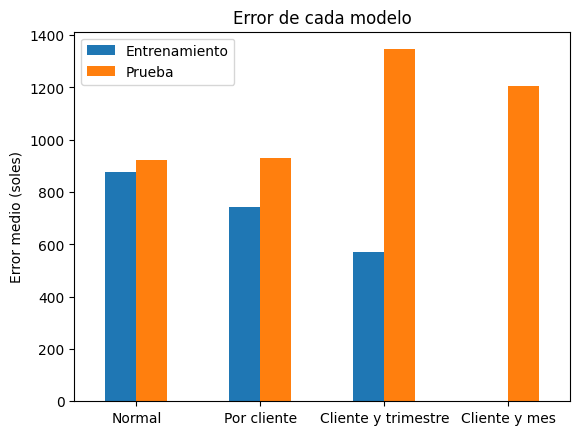

In [8]:
resultados = pd.DataFrame(
    {"Entrenamiento": [878, 741, 570, 0], "Prueba": [921, 930, 1346, 1207]},
    index=["Normal", "Por cliente", "Cliente y trimestre", "Cliente y mes"],
)

resultados.plot(
    kind="bar",
    title="Error de cada modelo",
    ylabel="Error medio (soles)",
    rot=0,
)
plt.show()

### 4. ¿Qué modelo elegirías?

Mira tu gráfico. ¿Cuál elegirías, y con qué cifra lo justificas? Responde en un comentario.

In [9]:
# El normal: empata con el de por cliente (921 y 930), y es más simple. Los otros fallan más.
# El de 3,498 falla menos en prueba que el de 1,188: más variables no empeoran siempre en
# línea recta. Lo que importa es que el error de entrenamiento ya no dice nada.
# Pero ojo: en el episodio 1.5, una regla simple le ganó con 827.

### 5. ¿Sobreajuste o no?

Responde en un comentario:

- a) Error de S/ 300 en entrenamiento y S/ 320 en prueba, con una línea base de S/ 800.
- b) Error de S/ 50 en entrenamiento y S/ 900 en prueba, con una línea base de S/ 800.
- c) Error de S/ 780 en entrenamiento y S/ 790 en prueba, con una línea base de S/ 800.

In [10]:
# a) No: los dos errores se parecen, y le gana con claridad a la línea base.
# b) Sí: es mucho mejor en entrenamiento, y en prueba es peor que la línea base.
# c) No hay sobreajuste, pero tampoco aporta: casi no le gana a la línea base.

## 🎉 ¡Bien hecho!

Nos vemos en el **episodio 1.7: Clasificación, ¿qué crédito revisamos primero?**

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0